# 01 · Ingest and harmonise the four datasets


**This notebook** turns four published, already-processed proteomics tables into one matrix with one meaning:

| | |
|---|---|
| rows | samples (`dataset:original_id`) |
| columns | b-numbers (K-12 MG1655 locus tags) |
| values | fraction of total protein **mass** (each sample sums to ≈ 1) |

Why each step exists

1. **One COG annotation for all datasets** – a b-number must belong to the same functional group in every study, so the annotation comes from one external source (UniProt → COG 2020), cached on disk with its checksum.
2. **One loader per paper, one output schema** – all file, sheet and column names are in `config.yml`; sample metadata that papers give only in text are in `metadata/*.tsv` with a source column. Nothing is typed into code.
3. **Same unit everywhere** – Schmidt 2016 reports copies per cell; it is converted to mass fraction of the measured proteome, `N·MW / Σ(N·MW)`, which needs no cell-volume or dry-weight assumption and is the quantity the other three studies report.
4. **Explicit value semantics** – `> 0` quantified, `0` in the table but not detected, `NaN` not in that dataset's table. Zeros are *not* turned into missing values here.
5. **Everything dropped is counted** – unmapped accessions, invalid loci, samples without a data column.

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


## 1 · COG annotation table 

The first run downloads two files into `data/annotation/` and records URL, date, UniProt release and SHA-256 in `provenance.json`. Later runs read the cached files, so the analysis does not change when the databases are updated. Commit the cached files to the repository.

In [2]:
annotation_table = annotation.build_annotation(cfg)          # downloads only if the files are not cached

with_cog = annotation_table["COG_Categories"] != ""
print(f"b-numbers in annotation        : {len(annotation_table)}")
print(f"with at least one COG category : {with_cog.sum()} ({with_cog.mean():.1%})")
print(f"with more than one category    : {(annotation_table['COG_Categories'].str.len() > 1).sum()}")
print(f"COG ids not found in COG 2020  : {(annotation_table['COG_IDs_not_in_COG2020'] != '').sum()} proteins")
print(f"b-numbers with >1 UniProt entry: {(annotation_table['n_entries_for_locus'] > 1).sum()} (first accession kept)")
display(annotation_table.head())

b-numbers in annotation        : 4402
with at least one COG category : 3677 (83.5%)
with more than one category    : 489
COG ids not found in COG 2020  : 0 proteins
b-numbers with >1 UniProt entry: 1 (first accession kept)


,b_number,UniProt_Accession,Gene_Name,Mass_Da,COG_IDs,COG_IDs_not_in_COG2020,COG_Categories,n_entries_for_locus
3155,b0001,P0AD86,thrL,2138,,,,1
11,b0002,P00561,thrA,89120,COG0460;COG0527,,E,1
1636,b0003,P00547,thrB,33624,COG0083,,E,1
1642,b0004,P00934,thrC,47114,COG0498,,E,1
4212,b0005,P75616,yaaX,11355,,,,1


## 2 · Load each dataset with its own loader

Each loader returns the same object (`X`, `obs`, `genes`, `log`). Warnings below are deliberate: a sample that is listed in the metadata but has no column in the configured sheets is reported, never silently skipped.

In [3]:
datasets = [
    ingest.load_schmidt(cfg, annotation_table),
    ingest.load_mori(cfg),
    ingest.load_wu(cfg),
    ingest.load_zhu(cfg),
]
report = ingest.ingest_report(datasets)

display(report)

c:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation\src\proteome_alloc\ingest.py:142: UserWarning: mori_2021: 4 sample(s) listed in the metadata table have no data column in the configured files/sheets: ['Lib-31-A1', 'Lib-31-A2', 'Lib-32-A1', 'Lib-32-A2']
  warnings.warn(message)
c:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation\src\proteome_alloc\ingest.py:142: UserWarning: wu_2023: 1 sample(s) listed in the metadata table have no data column in the configured files/sheets: ['A3']
  warnings.warn(message)


,n_samples,n_loci,detected_per_sample_median,sample_sum_min,sample_sum_max,rows_invalid_locus_dropped,duplicated_locus_rows_summed,cells_non_numeric_set_to_zero,samples_in_metadata_not_in_files
schmidt_2016,2.0,1986.0,1986.0,0.99554,0.995841,0.0,1.0,0.0,NaN
mori_2021,19,4324,2024.0,1.0,1.0,0,0,0,"[Lib-31-A1, Lib-31-A2, Lib-32-A1, Lib-32-A2]"
wu_2023,21,4324,1792.0,1.0,1.0,1,0,0,[A3]
zhu_2025,12,4350,1434.5,0.998427,0.999537,39,0,0,[]


In [4]:
# Full per-dataset log: every dropped row / sample, and where each Zhu sample was found
for d in datasets:
    print(f"\n=== {d.name} ===")
    for key, value in d.log.items():
        print(f"  {key}: {value}")


=== schmidt_2016 ===
  rows_mw_filled_from_uniprot: 0
  rows_dropped_no_mw_or_no_copies: 19
  rows_unmapped_accession_dropped: 32
  mass_fraction_lost_unmapped_per_sample: {'LB': 0.00416, 'Glucose': 0.00446}
  rows_invalid_locus_dropped: 0
  mass_fraction_in_invalid_locus_rows_max: 0.0
  cells_non_numeric_set_to_zero: 0
  duplicated_locus_rows_summed: 1
  sample_sum_min: 0.9955403249650412
  sample_sum_max: 0.9958413498064453
  samples_outside_sum_bounds: {}
  n_samples: 2
  n_loci: 1986
  detected_per_sample_median: 1986.0

=== mori_2021 ===
  abundance_file_sheets_available: ['Description', 'EV8-AbsoluteMassFractions-1']
  samples_file_sheets_available: ['Description', 'EV2-Samples-1']
  samples_other_strain_dropped: 30
  samples_in_metadata_not_in_files: ['Lib-31-A1', 'Lib-31-A2', 'Lib-32-A1', 'Lib-32-A2']
  samples_without_growth_rate: ['Lib-14', 'Lib-19', 'Lib-20', 'Lib-21', 'Lib-22', 'Lib-31-A1', 'Lib-31-A2', 'Lib-32-A1', 'Lib-32-A2']
  rows_invalid_locus_dropped: 0
  mass_fract

**Check before continuing**

* `sample_sum_min / max` must be ≈ 1 for every dataset. A different value means a unit problem or a missing sheet.
* `samples_in_metadata_not_in_files` should only contain samples you expect to be absent. For Mori 2021, compare `abundance_file_sheets_available` with `abundance_sheets` in `config.yml`: if the nutrient-limitation series are in another sheet, add that sheet to the config and re-run.
* Schmidt: `mass_fraction_lost_unmapped_per_sample` is the share of protein mass that could not be given a b-number.

## 3 · Merge on b-number

Outer join: a protein that one platform never reports stays in the matrix as `NaN` for that dataset. The protein table records, per dataset, whether the locus is in the table and in what fraction of samples it was quantified. This replaces the sparsity filter of the earlier version, which ran while non-detections were still stored as 0 and therefore removed nothing.

In [5]:
X, obs, var = ingest.combine(datasets)

print("Merged matrix (samples x proteins):", X.shape)
state = pd.DataFrame({
    "quantified (>0)": (X > 0).groupby(obs["Dataset_Source"]).sum().sum(axis=1),
    "in table, not detected (0)": (X == 0).groupby(obs["Dataset_Source"]).sum().sum(axis=1),
    "not in dataset table (NaN)": X.isna().groupby(obs["Dataset_Source"]).sum().sum(axis=1),
})
state["share quantified"] = state["quantified (>0)"] / state.sum(axis=1)
display(state)
display(var["n_datasets_in_table"].value_counts().sort_index().rename("proteins present in k dataset tables").to_frame())

Merged matrix (samples x proteins): (54, 4449)


,quantified (>0),"in table, not detected (0)",not in dataset table (NaN),share quantified
Dataset_Source,,,,
mori_2021,38501,43655,2375,0.455466
schmidt_2016,3972,0,4926,0.446392
wu_2023,36965,53839,2625,0.395648
zhu_2025,17399,34801,1188,0.325897


,proteins present in k dataset tables
n_datasets_in_table,
1,124
2,100
3,2240
4,1985


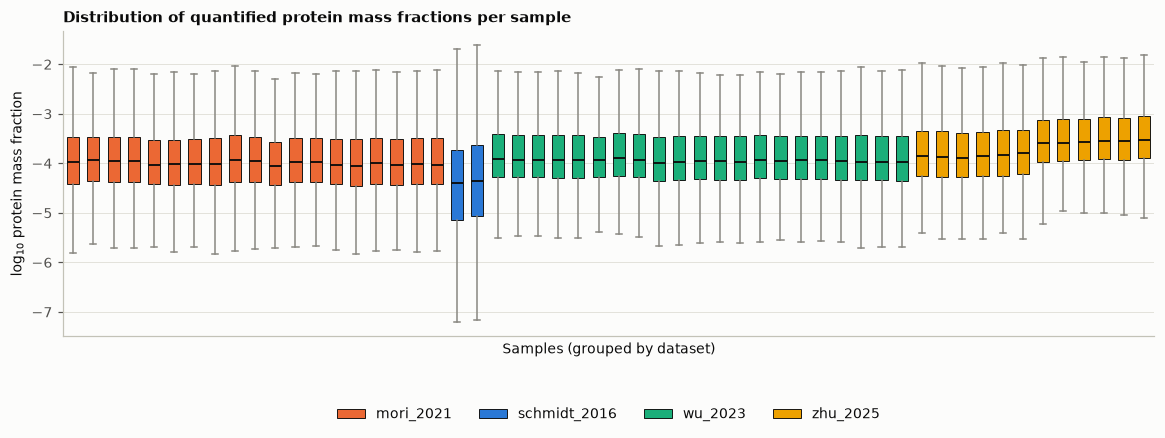

In [6]:
fig = plots.plot_distributions(X, obs, cfg.figures / "01_mass_fraction_distributions.png")
plt.show()

Box plots are used because the question at this stage is about **distributions** (dynamic range, depth, gross offsets between platforms), not about individual proteins. A dataset whose boxes sit clearly above or below the others would indicate a unit mismatch; the pairwise check in notebook 02 quantifies this.

## 4 · Save the harmonised data and the run record

In [7]:
paths = ingest.save_processed(cfg, X, obs, var)
report.astype(str).to_csv(cfg.tables / "01_ingest_report.tsv", sep="\t")

inputs = {name: digest for d in datasets for name, digest in d.files.items()}
for file in sorted(cfg.path("annotation_dir").glob("*")):
    if file.is_file():
        inputs[f"annotation/{file.name}"] = config.sha256(file)
for file in sorted((cfg.root / "metadata").glob("*.tsv")):
    inputs[f"metadata/{file.name}"] = config.sha256(file)

config.log_run(cfg, "01_ingest_harmonise",
               params={"datasets": cfg["datasets"], "ingest": cfg["ingest"], "annotation": cfg["annotation"]},
               inputs=inputs, outputs=paths,
               notes={d.name: d.log for d in datasets})
print("Written:", *[p.relative_to(cfg.root) for p in paths], sep="\n  ")

try:                                   # optional: AnnData copy for scanpy users
    ingest.to_anndata(X, obs, var).write_h5ad(cfg.path("processed_dir") / "proteome.h5ad")
    print("  data/processed/proteome.h5ad")
except ImportError:
    print("anndata not installed - h5ad export skipped (not needed by the pipeline).")

Written:
  data\processed\mass_fractions.tsv.gz
  data\processed\sample_metadata.tsv
  data\processed\protein_table.tsv
anndata not installed - h5ad export skipped (not needed by the pipeline).


In [8]:
# Independent check: Schmidt copies/cell -> mass fraction, recomputed from the raw Excel
c = cfg["datasets"]["schmidt_2016"]
raw = pd.read_excel(cfg.path("raw_dir") / c["file"], sheet_name=c["abundance_sheet"], skiprows=c["skiprows"])
prefix = c["copies_prefix"].format(strain=c["strain"])

acc_to_b = (annotation_table.drop_duplicates("UniProt_Accession")
            .set_index("UniProt_Accession")["b_number"])

for sample in ["LB", "Glucose"]:
    copies = pd.to_numeric(raw[prefix + sample], errors="coerce")
    mw = pd.to_numeric(raw[c["mw_col"]], errors="coerce")
    ok = copies.notna() & mw.notna()
    mass = copies[ok] * mw[ok]                      # copies x MW = protein mass per cell (relative)
    manual = mass / mass.sum()                      # share of total quantified protein mass
    loci = raw.loc[ok, c["accession_col"]].astype(str).str.strip().map(acc_to_b)
    manual = manual.groupby(loci).sum()             # accessions -> b-numbers

    pipeline = X.loc[f"schmidt_2016:{sample}"].dropna()
    shared = manual.index.intersection(pipeline.index)
    print(f"{sample:8s} sum of pipeline fractions = {pipeline.sum():.6f} | "
          f"max |manual - pipeline| = {(manual[shared] - pipeline[shared]).abs().max():.2e} | "
          f"proteins compared = {len(shared)}")

# Plausibility: the 10 most abundant Schmidt proteins vs the same proteins in glucose in Wu and Zhu
glc = X.loc["schmidt_2016:Glucose"]
top = glc.sort_values(ascending=False).head(10).index
wu = X.loc[obs.index[(obs["Dataset_Source"] == "wu_2023") & (obs["Condition_ID"] == "Glucose_Minimal")]].mean()
zhu = X.loc[obs.index[(obs["Dataset_Source"] == "zhu_2025") & (obs["Condition_ID"] == "Glucose_37C")]].mean()
display(pd.DataFrame({
    "gene": var.loc[top, "Gene_Name"],
    "Schmidt glucose (%)": glc[top] * 100,
    "Wu glucose (%)": wu[top] * 100,
    "Zhu glucose (%)": zhu[top] * 100,
}).round(3))

LB       sum of pipeline fractions = 0.995841 | max |manual - pipeline| = 0.00e+00 | proteins compared = 1986
Glucose  sum of pipeline fractions = 0.995540 | max |manual - pipeline| = 0.00e+00 | proteins compared = 1986


,gene,Schmidt glucose (%),Wu glucose (%),Zhu glucose (%)
b_number,,,,
b3339,tufA,8.321,1.804,0.592
b3829,metE,3.281,5.027,2.022
b3340,fusA,2.428,1.145,1.074
b0911,rpsA,1.399,1.075,1.489
b2414,cysK,1.303,0.486,0.496
b2779,eno,1.261,0.747,0.707
b0957,ompA,1.239,1.242,0.956
b1136,icd,1.184,1.420,1.003
b4000,hupA,1.091,0.260,0.166


### Cross-check: are Schmidt values on the same scale as Wu and Zhu?

Two very abundant, well-measured protein pairs (EF-Tu = *tufA*+*tufB*, HU = *hupA*+*hupB*) are compared in glucose minimal medium. If the copies-per-cell → mass-fraction conversion above is correct, the three studies should report similar percentages of the proteome for these proteins.

In [9]:
pairs = {"EF-Tu": ["tufA", "tufB"], "HU": ["hupA", "hupB"]}
rows = {}
for name, genes in pairs.items():
    loci = var.index[var["Gene_Name"].isin(genes)]
    rows[name] = {"Schmidt glucose (%)": glc[loci].sum() * 100,
                  "Wu glucose (%)": wu[loci].sum() * 100,
                  "Zhu glucose (%)": zhu[loci].sum() * 100,
                  "genes found": ", ".join(var.loc[loci, "Gene_Name"])}
display(pd.DataFrame(rows).T)

,Schmidt glucose (%),Wu glucose (%),Zhu glucose (%),genes found
EF-Tu,8.321217,3.609892,1.1847,"tufA, tufB"
HU,1.411816,0.495215,0.18395,"hupB, hupA"


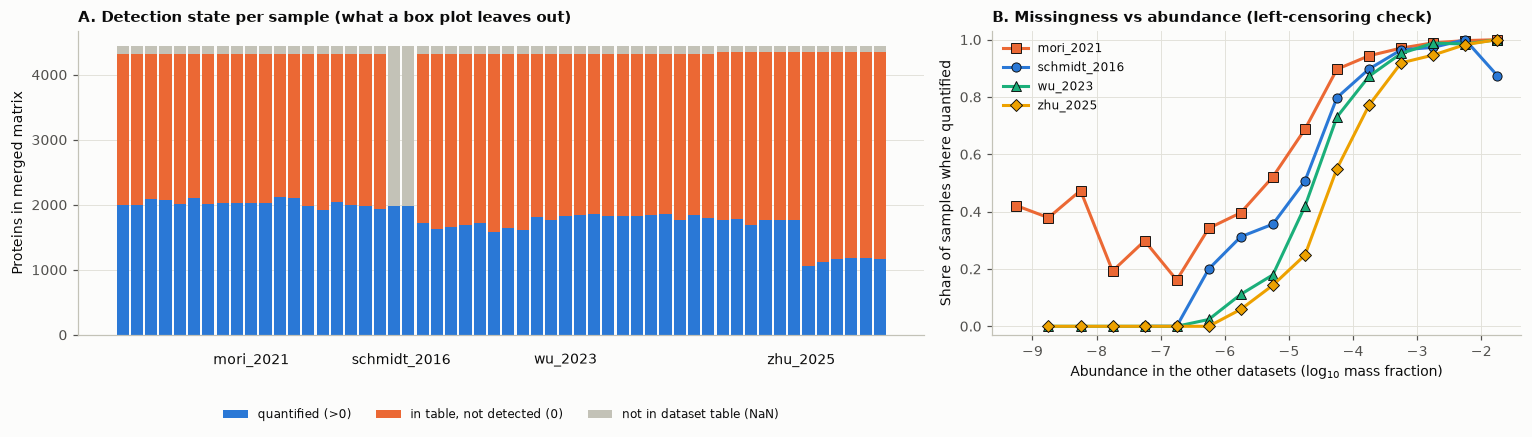

,proteins never quantified here (seen elsewhere),their share of proteome mass in the other datasets (%)
mori_2021,157,0.24
schmidt_2016,536,3.54
wu_2023,474,1.11
zhu_2025,718,3.02


In [10]:
# ---- Missingness: what the box plot does not show -----------------------------------------
# (1) detection state of every protein in every sample; (2) is missingness related to abundance (MNAR)?
# (3) how much proteome mass do a dataset's missing proteins carry in the other datasets?
order = obs.sort_values("Dataset_Source", kind="stable").index
dataset_of = obs["Dataset_Source"]
names = list(pd.unique(dataset_of.loc[order]))

state = pd.DataFrame({
    "quantified (>0)": (X > 0).sum(axis=1),
    "in table, not detected (0)": (X == 0).sum(axis=1),
    "not in dataset table (NaN)": X.isna().sum(axis=1),
}).loc[order]

# MNAR check: detection rate in dataset d versus abundance measured in the OTHER datasets
# (leave-dataset-out reference avoids circularity: a protein's own detection does not set its abundance)
log_q = np.log10(X.where(X > 0))
bins = np.arange(np.floor(np.nanmin(log_q.to_numpy())), np.ceil(np.nanmax(log_q.to_numpy())) + 0.5, 0.5)
detection, missing_mass = {}, {}
for d in names:
    inside = dataset_of == d
    reference = log_q.loc[~inside].mean(axis=0)                     # abundance in the other datasets
    detected = (X.loc[inside] > 0).mean(axis=0)                     # NaN and 0 both count as not detected
    keep = reference.notna()
    detection[d] = detected[keep].groupby(pd.cut(reference[keep], bins), observed=True).mean()
    never = keep & (detected == 0)                                   # never quantified in d, seen elsewhere
    other_mass = X.loc[~inside].fillna(0).mean(axis=0)               # mean mass fraction in the other datasets
    missing_mass[d] = {"proteins never quantified here (seen elsewhere)": int(never.sum()),
                       "their share of proteome mass in the other datasets (%)": round(100 * other_mass[never].sum(), 2)}
detection = pd.DataFrame(detection)
detection.index = [interval.mid for interval in detection.index]

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(state))
for column, colour in zip(state.columns, ["#2a78d6", "#eb6834", "#c3c2b7"]):
    left.bar(range(len(state)), state[column], bottom=bottom, color=colour, width=0.85, label=column)
    bottom += state[column].to_numpy()
for d in names:                                                      # dataset labels under the bars
    idx = np.flatnonzero(dataset_of.loc[order].to_numpy() == d)
    left.text(idx.mean(), -0.06, d, transform=left.get_xaxis_transform(), ha="center", va="top")
left.set_xticks([]); left.set_ylabel("Proteins in merged matrix")
left.set_title("A. Detection state per sample (what a box plot leaves out)")
left.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8)
for d in names:
    colour, marker = plots._style(d)
    right.plot(detection.index, detection[d], color=colour, marker=marker, markersize=6,
               markeredgecolor="#0b0b0b", markeredgewidth=0.6, linewidth=2, label=d)
right.set_xlabel("Abundance in the other datasets (log$_{10}$ mass fraction)")
right.set_ylabel("Share of samples where quantified")
right.set_ylim(-0.03, 1.03)
right.set_title("B. Missingness vs abundance (left-censoring check)")
right.legend(fontsize=8)
fig.tight_layout()
fig.savefig(cfg.figures / "01_missingness_detection_vs_abundance.png", dpi=200, bbox_inches="tight")
plt.show()

missing_mass = pd.DataFrame(missing_mass).T.astype({"proteins never quantified here (seen elsewhere)": int})
missing_mass.to_csv(cfg.tables / "01_missing_proteins_mass_share.tsv", sep="\t")
display(missing_mass)

In [11]:
# abundance at which each dataset reaches 50 % detection (linear interpolation on the curve)
for d in detection.columns:
    curve = detection[d].dropna()
    above = curve[curve >= 0.5]
    print(f"{d:14s} 50% detection at ~10^{np.interp(0.5, curve.values, curve.index):.2f}" if len(above) else d)

# very abundant proteins (elsewhere > 1% of proteome) that Schmidt never quantified
inside = obs["Dataset_Source"] == "schmidt_2016"
ref = log_q.loc[~inside].mean()
missed = ref[(ref > -2) & ((X.loc[inside] > 0).mean() == 0)]
display(var.loc[missed.index, ["Gene_Name"]].assign(log10_abundance_elsewhere=missed.round(2)))

mori_2021      50% detection at ~10^-5.34
schmidt_2016   50% detection at ~10^-4.77
wu_2023        50% detection at ~10^-4.62
zhu_2025       50% detection at ~10^-4.33


,Gene_Name,log10_abundance_elsewhere
b_number,,
b3980,tufB,-1.82
